## With this, i want to make the general analysis a little bit skinnier (it did not work lol)

In [1]:
## how many cores does the current jupyter server have?
n_tasks = 4

In [2]:
import sys
import os
import dask
from time import perf_counter
from pathlib import Path
import pandas as pd
import xarray as xr
import numpy as np
from tqdm.notebook import tqdm as notebook_tqdm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from joblib import Parallel, delayed

sys.path.insert(0, "/jetfs/home/gbrack/MSC_Thesis/fp_ana_tools/src")

from fp_ana_tools.read_binary import read_namelists, read_gridini
from fp_ana_tools.era5_io import read_met
from fp_ana_tools.era5_vertical import calculate_geometry, average_to_flexpart_layers, geometric_altitude

In [3]:
run_dir = Path(
    "/jetfs/scratch/gbrack/flexpart_output/"
    "new_delhi_30d_24h_hourly_releases_bigger_domain"
)

met_dir = Path("/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h")

surface_file = Path("/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_2015_04_05_06.nc")
radiation_dir = Path("/jetfs/scratch/gbrack/MSC/ERA5_FLEXPART_global_0.5deg_42vertlayers/2015")

grid_files = sorted(run_dir.glob("grid_time*.nc"))
assert len(grid_files) == 1

grid = xr.open_dataset(grid_files[0], chunks={"time": 1})
times_ini, times_fin, heights, lat, lon, age = read_namelists(run_dir)

In [4]:
release = 0
i = release - 1

print("Rückwärtsdauer [Tage]", age / 86400)
print("Anfangszeit [UTC]", times_ini[i])
print("Releasezeit [UTC]", times_fin[i])
print("FLEXPART-Schichten", len(heights) - 1)

Rückwärtsdauer [Tage] 30.0
Anfangszeit [UTC] 2015-04-26 00:00:00
Releasezeit [UTC] 2015-05-26 00:00:00
FLEXPART-Schichten 42


### Berechne Initial Budget

In [5]:
# read gridini
ds_ini = read_gridini(run_dir, times_ini, heights, lat, lon)
initial_times = ds_ini.valid_time.values

KeyboardInterrupt: 

In [ ]:
cp, Lv, g = 1004.6, 2501000.0, 9.81

def calculate_initial_release(release, initial_time, release_time, s_ini):
    #start = perf_counter()
    #tag = f"[Release {release:02d} | PID {os.getpid()}]"
    #print(f"{tag} gestartet", flush=True)

    weight_sum = s_ini.sum(skipna=False).item()

    #read_start = perf_counter()
    #print(f"{tag} lese ERA5", flush=True)
    met_ini = read_met(initial_time, met_dir).sel(
        latitude=s_ini.latitude.values,
        longitude=s_ini.longitude.values
    ).transpose("hybrid", "latitude", "longitude", "hybrid_half")
    #print(f"{tag} ERA5 geladen nach {perf_counter() - read_start:.1f} s", flush=True)

    height_full, height_half = calculate_geometry(
        met_ini,
        met_ini.a_half.values,
        met_ini.b_half.values
    )

    ground_altitude = geometric_altitude(
        met_ini.z.values.astype("float64")
    )

    energy_fields = {
        "cpT": cp * met_ini.t.values.astype("float64"),
        "Lvq": Lv * met_ini.q.values.astype("float64"),
        "gh": g * (height_full + ground_altitude)
    }

    initial_raw = {}
    for name, values in energy_fields.items():
        layer_mean = average_to_flexpart_layers(
            values, height_half, s_ini.height.values
        )
        field = s_ini.copy(data=layer_mean)
        initial_raw[name] = (s_ini * field).sum(skipna=False).item()

    mse_raw = sum(initial_raw.values())
    
    #print(f"{tag} fertig nach {perf_counter() - start:.1f} s", flush=True)
    return {
        "release": release,
        "release_time": release_time,
        "initial_time": initial_time,
        "weight_sum": weight_sum,
        "cpT_ini_raw": initial_raw["cpT"],
        "Lvq_ini_raw": initial_raw["Lvq"],
        "gh_ini_raw": initial_raw["gh"],
        "mse_ini_raw": mse_raw,
        "mse_ini_normalized": mse_raw / weight_sum if weight_sum > 0 else float("nan"),
    }

    #print(f"Release {release} fertig: Gewicht: {weight_sum:.6f}")

In [ ]:
results = Parallel(n_jobs=1, backend="loky", return_as="generator_unordered")(
    delayed(calculate_initial_release)(
        i + 1,
        initial_time,
        times_fin[i],
        ds_ini.sensitivity.isel(valid_time=i, drop=True),
    )
    for i, initial_time in enumerate(initial_times)
)

initial_results = []

with notebook_tqdm(
    total=len(initial_times), desc="Anfangs-MSE", unit="Release"
) as bar:
    for result in results:
        initial_results.append(result)
        bar.update(1)

initial_budget = pd.DataFrame(initial_results).set_index("release").sort_index()
initial_budget

Anfangs-MSE:   0%|          | 0/25 [00:00<?, ?Release/s]

KeyboardInterrupt: 

In [ ]:
# calculating the target MSE
# define receptor (New Delhi)
receptor_lon = 77.2
receptor_lat = 28.6
receptor_height_agl = 50.0

end_results = []

# calculate End MSE terms for each release time at the defined receptor
for release, release_time in notebook_tqdm(initial_budget["release_time"].items(), 
                                  total=len(initial_budget), 
                                  desc="End-MSE", 
                                  unit="Release"):
    # read era5
    met_end = read_met(release_time, met_dir).interp(latitude=[receptor_lat],
                                                     longitude=[receptor_lon])

    height_full_end, _ = calculate_geometry(
        met_end, met_end.a_half.values, met_end.b_half.values
    )

    z_agl = height_full_end[:, 0, 0][::-1]
    if not z_agl[0] <= receptor_height_agl <= z_agl[-1]:
        raise ValueError(f"Receptor height out of release profile at release {release}")

    temperature = np.interp(
        receptor_height_agl,
        z_agl,
        met_end.t.values[:, 0, 0][::-1]
    )
    humidity = np.interp(
        receptor_height_agl, z_agl, met_end.q.values[:, 0, 0][::-1]
    )

    ground_altitude = geometric_altitude(met_end.z.item())

    cpT_end = cp * temperature
    Lvq_end = Lv * humidity
    gh_end = g * (ground_altitude + receptor_height_agl)

    end_results.append({
        "release": release,
        "cpT_end": cpT_end,
        "Lvq_end": Lvq_end,
        "gh_end": gh_end,
        "mse_end": cpT_end + Lvq_end + gh_end
    })

end_budget = pd.DataFrame(end_results).set_index("release")
boundary_budget = initial_budget.join(end_budget, validate="one_to_one")

boundary_budget[["release_time", "weight_sum", "mse_ini_raw", "mse_ini_normalized", "mse_end"]]

End-MSE:   0%|          | 0/25 [00:00<?, ?Release/s]

,release_time,weight_sum,mse_ini_raw,mse_ini_normalized,mse_end
release,,,,,
1,2015-05-25 00:00:00,0.993808,321812.500683,323817.447790,324186.057117
2,2015-05-25 01:00:00,0.994059,321530.048934,323451.619597,324290.351133
3,2015-05-25 02:00:00,0.994337,321669.263972,323501.121040,327681.165508
4,2015-05-25 03:00:00,0.995118,321930.292271,323509.730239,331798.778343
5,2015-05-25 04:00:00,0.995028,321860.721884,323468.934031,334838.474366
6,2015-05-25 05:00:00,0.994730,321603.812961,323307.652778,335667.156983
7,2015-05-25 06:00:00,0.994278,321615.741003,323466.477937,335189.227890
8,2015-05-25 07:00:00,0.994310,321313.533926,323152.286005,333764.686139
9,2015-05-25 08:00:00,0.994080,321135.135367,323047.597948,332762.027242


In [ ]:
boundary_budget["delta_mse_est"] = (
    boundary_budget["mse_end"] - boundary_budget["mse_ini_normalized"]
)

boundary_budget["initial_normalization_shift"] = (
    boundary_budget["mse_ini_normalized"] - boundary_budget["mse_ini_raw"]
)

energy_cols = ["delta_mse_est", "initial_normalization_shift"]

display_budget = boundary_budget[["release_time", *energy_cols]].copy()
display_budget[energy_cols] = display_budget[energy_cols] / 1000
display_budget

,release_time,delta_mse_est,initial_normalization_shift
release,,,
1,2015-05-25 00:00:00,0.368609,2.004947
2,2015-05-25 01:00:00,0.838732,1.921571
3,2015-05-25 02:00:00,4.180044,1.831857
4,2015-05-25 03:00:00,8.289048,1.579438
5,2015-05-25 04:00:00,11.369540,1.608212
6,2015-05-25 05:00:00,12.359504,1.703840
7,2015-05-25 06:00:00,11.722750,1.850737
8,2015-05-25 07:00:00,10.612400,1.838752
9,2015-05-25 08:00:00,9.714429,1.912463


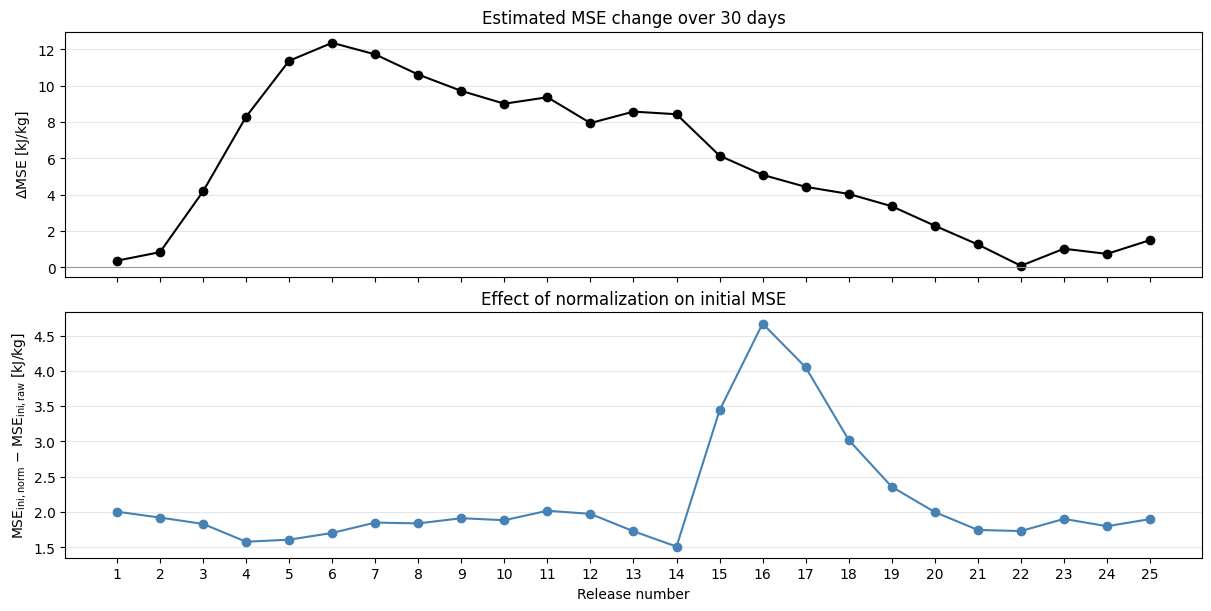

In [ ]:
fig, (ax_mse, ax_norm) = plt.subplots(
    2, 1, sharex=True, figsize=(12, 6), layout="constrained"
)

release = display_budget.index

ax_mse.plot(release, display_budget["delta_mse_est"], "o-", color="black")
ax_mse.set_title("Estimated MSE change over 30 days")
ax_mse.set_ylabel(r"$\Delta$MSE [kJ/kg]")
ax_mse.axhline(0, color="0.6", linewidth=0.8)

ax_norm.plot(
    release, display_budget["initial_normalization_shift"],
    "o-", color="steelblue",
)
ax_norm.set_title("Effect of normalization on initial MSE")
ax_norm.set_ylabel(r"MSE$_{\mathrm{ini,norm}}$ − MSE$_{\mathrm{ini,raw}}$ [kJ/kg]")
ax_norm.set_xlabel("Release number")
ax_norm.set_xticks(release)

for ax in (ax_mse, ax_norm):
    ax.grid(axis="y", alpha=0.3)

### Since normalization adds quite a bit of initial MSE, we have to assume that the particles outside the domain can not be neglected, we will therefore be using the normalized initial conditions in order to diagnose the MSE uptake

In [ ]:
delta_cpT = boundary_budget.cpT_end - boundary_budget.cpT_ini_raw / boundary_budget.weight_sum
delta_Lvq = boundary_budget.Lvq_end - boundary_budget.Lvq_ini_raw / boundary_budget.weight_sum
delta_gh = boundary_budget.gh_end - boundary_budget.gh_ini_raw / boundary_budget.weight_sum

boundary_budget["delta_cpT"] = delta_cpT
boundary_budget["delta_Lvq"] = delta_Lvq
boundary_budget["delta_gh"] = delta_gh

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards')

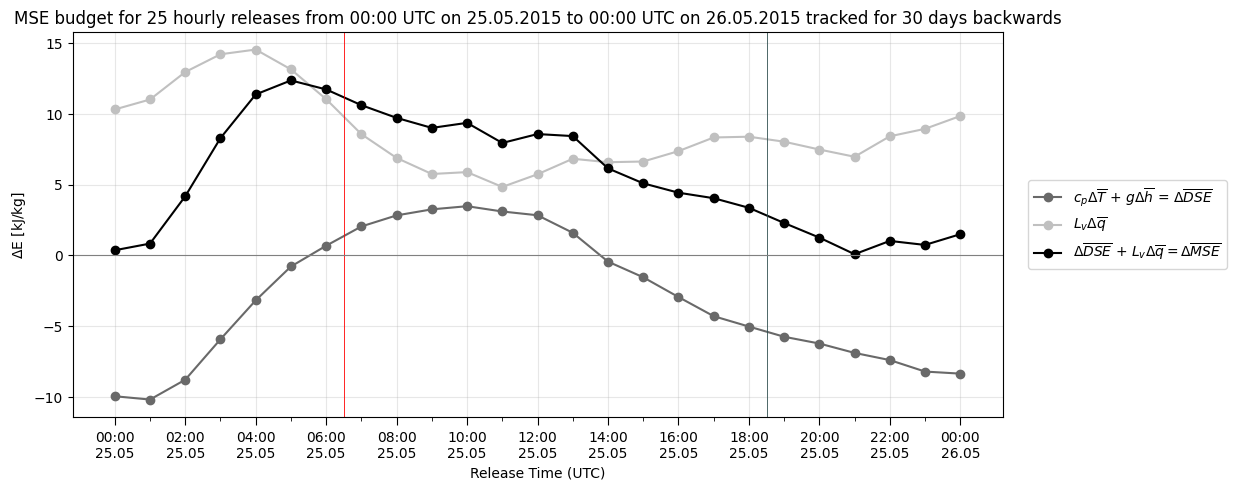

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

release_time = pd.to_datetime(boundary_budget.release_time)
label_every = 2

ax.plot(release_time, 
        (boundary_budget.delta_cpT + boundary_budget.delta_gh) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(release_time,
        boundary_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(release_time,
        boundary_budget.delta_mse_est / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

day = release_time.iloc[0].normalize()
ax.axvline(day + pd.Timedelta(hours=6, minutes=30),
           color="red", linewidth=0.6)
ax.axvline(day + pd.Timedelta(hours=18, minutes=30),
           color="darkslategrey", linewidth=0.6)
ax.set_xticks(release_time.iloc[::label_every])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m"))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Release Time (UTC)")

ax.axhline(0, color="gray", linewidth=0.8)
#ax.grid(axis="y", alpha=0.3)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards")

## Contribution of Surface Fluxes

In [ ]:
surface = xr.open_dataset(surface_file, chunks={})[["sshf", "slhf"]]
surface = surface.rename({"valid_time": "time"})

# ERA5-Timestamp of Interval-End has to be shifted to Interval-Start
surface = surface.assign_coords(time=surface.time - pd.Timedelta(hours=1))

# since ERA and FLEXPART grids do not quite line up perfectly (one has lon=-180, the other lon=180), we need to shift that one column to the other end of the dataset
flux_lon = grid.longitude.values.copy()
if 180 not in surface.longitude.values and -180 in surface.longitude.values:
    flux_lon[flux_lon == 180] = -180

surface_aligned = surface.sel(
    latitude=grid.latitude.values,
    longitude=flux_lon
).assign_coords(longitude=grid.longitude.values)

In [ ]:
# Turn surface fluxes into sources for the lowest 100m (this is the formula)
surface_source = xr.Dataset({
    "sensible": -surface_aligned.sshf / (3600 * 100),
    "latent": -surface_aligned.slhf / (3600 * 100)
})

surface_sensitivity = (
    grid.spec001_mr.isel(nageclass=0, drop=True).sel(height=100, drop=True)
)

In [ ]:
# Calculate contributions per release

surface_results = []
release_maps = []

for release, row  in notebook_tqdm(boundary_budget.iterrows(), total=len(boundary_budget), desc="Surface Budget", unit="Release"):
    # get hours
    hours = pd.date_range(row.initial_time, row.release_time, freq="1h", inclusive="left")
    assert len(hours) == 720, f"Release {release}: {len(hours)} hours"

    # select sensitivity fields for specific release and time frame
    sensitivity = surface_sensitivity.isel(pointspec=int(release) - 1, drop=True).sel(time=hours)

    # check alignment of surface source and sensitivity
    source, sensitivity = xr.align(surface_source.sel(time=hours), sensitivity, join="exact")

    # rechunk source and sensitivity in order to load the same fields
    chunks = {"time": 24, "latitude": -1, "longitude": -1}
    source = source.chunk(chunks)
    sensitivity = sensitivity.chunk(chunks)

    # calculate the map
    release_map = xr.where(
        sensitivity == 0, 0.0, source * sensitivity
    ).sum("time", skipna=False).compute()
    release_maps.append(release_map.expand_dims(release=[release]))

    total = release_map.sum(("latitude", "longitude"), skipna=False)
    surface_results.append({
        "release": release,
        "sfc_sensible": total.sensible.item(),
        "sfc_latent": total.latent.item()
    })

surface_maps = xr.concat(release_maps, dim="release")
surface_budget = pd.DataFrame(surface_results).set_index("release")
surface_budget["sfc_total"] = (
    surface_budget["sfc_sensible"] + surface_budget["sfc_latent"]
)
boundary_budget[surface_budget.columns] = surface_budget
display(surface_budget / 1000)

Surface Budget:   0%|          | 0/25 [00:00<?, ?Release/s]

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards')

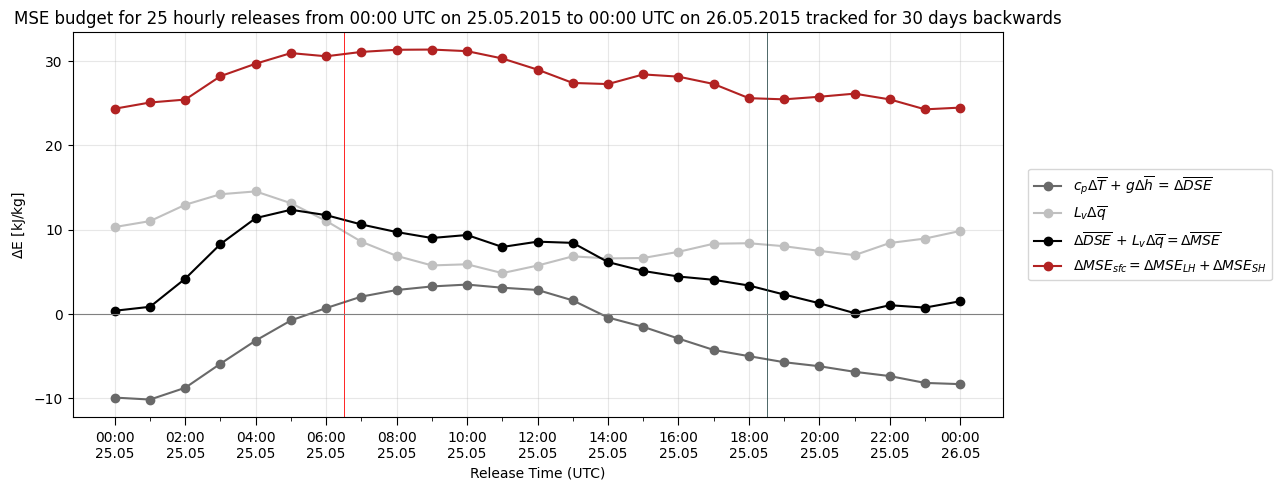

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(release_time, 
        (boundary_budget.delta_cpT + boundary_budget.delta_gh) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(release_time,
        boundary_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(release_time,
        boundary_budget.delta_mse_est / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.plot(release_time,
        boundary_budget.sfc_total / 1000,
        marker="o", label=r'$\Delta MSE_{sfc} = \Delta MSE_{LH} + \Delta MSE_{SH}$', color="firebrick")

day = release_time.iloc[0].normalize()
ax.axvline(day + pd.Timedelta(hours=6, minutes=30),
           color="red", linewidth=0.6)
ax.axvline(day + pd.Timedelta(hours=18, minutes=30),
           color="darkslategrey", linewidth=0.6)
ax.set_xticks(release_time.iloc[::label_every])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m"))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Release Time (UTC)")

ax.axhline(0, color="gray", linewidth=0.8)
#ax.grid(axis="y", alpha=0.3)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards")

## Radiation Forcing

In [ ]:
# construct radiation filenames
radiation_files = [radiation_dir / f"radiation_fp_2015{month}.nc" for month in ("04", "05")]

# open radiation files (chunked)
radiation = xr.open_mfdataset(
    radiation_files,
    combine="by_coords",
    data_vars="minimal",
    coords="minimal",
    join="exact",
    chunks={"time": 1}
)

# drop s22 coords
s22 = grid.spec001_s22.isel(nageclass=0, drop=True)

# get releases, start times, end times and all hours
releases = boundary_budget.index.to_numpy(dtype=int)
starts = boundary_budget.initial_time.to_numpy()
ends = boundary_budget.release_time.to_numpy()
hours = pd.date_range(starts.min(), ends.max(), freq="h", inclusive="left")

# same problem as above
rad_lon = s22.longitude.values.copy()
if 180 not in radiation.longitude.values and -180 in radiation.longitude.values:
    rad_lon[rad_lon == 180] = -180

# align sources to s22
sources = (
    radiation[["sw_source", "lw_source"]].sel(
        time=hours,
        height=s22.height.values,
        latitude=s22.latitude.values,
        longitude=rad_lon
    ).assign_coords(longitude=s22.longitude.values)
    .transpose("time", "height", "latitude", "longitude")
)

# select s22 hours and transpose the same way as sources
s22 = s22.sel(time=hours).transpose("time", "pointspec", "height", "latitude", "longitude")

# sanity check
sources, s22 = xr.align(sources, s22, join="exact")

In [ ]:
map_shape = (len(releases), s22.sizes["latitude"], s22.sizes["longitude"])

def calculate_radiation_hour(active, weights, sw, lw):
    maps = {}

    for name, field in (("rad_sw", sw), ("rad_lw", lw)):
        missing = ~np.isfinite(field)
        has_missing = missing.any()
        if has_missing:
            field = np.where(missing, 0.0, field)

        hour_map = np.einsum("rhyx,hyx->ryx", weights, field, dtype=np.float64)

        if has_missing:
            for release_map, weight in zip(hour_map, weights):
                release_map[((weight != 0) & missing).any(axis=0)] = np.nan

        maps[name] = hour_map

    return active, maps

def run_radiation(indices, n_workers, batch_size=4):
    accumulated = {
        "rad_sw": np.zeros(map_shape, dtype=np.float64),
        "rad_lw": np.zeros(map_shape, dtype=np.float64)
    }
    hours_used = np.zeros(len(releases), dtype=int)

    with notebook_tqdm(total=len(indices), desc=f"Radiation ({n_workers} Workers)", unit="h") as bar:
        for offset in range(0, len(indices), batch_size):
            batch = indices[offset:offset + batch_size]
            tasks = []

            for i in batch:
                hour = hours.values[i]
                active = np.flatnonzero((starts <= hour) & (hour < ends))
                if active.size == 0:
                    continue

                weights = s22.isel(time=i, pointspec=releases[active] - 1).data
                source_hour = sources.isel(time=i)

                tasks.append(dask.delayed(calculate_radiation_hour)(
                    active,
                    weights,
                    source_hour["sw_source"].data,
                    source_hour["lw_source"].data
                ))

            results = dask.compute(*tasks, scheduler="threads", num_workers=n_workers)
            for active, maps in results:
                for name, hour_map in maps.items():
                    accumulated[name][active] += hour_map
                hours_used[active] += 1

            bar.update(len(batch))

        return accumulated, hours_used

In [ ]:
middle = len(hours) // 2
test_hours = range(middle, middle + 8)
timings = {}

for n_workers in (1, 2, 4):
    t0 = perf_counter()
    test_maps, test_counts = run_radiation(test_hours, n_workers)
    timings[n_workers] = perf_counter() - t0

    np.testing.assert_array_equal(test_counts, np.full(len(releases), 8))
    assert np.any(
        np.isfinite(test_maps["rad_lw"]) & (test_maps["rad_lw"] != 0)
    ), "The LW-Maps don't contain a finite absolute value that is different from 0"

    if n_workers == 1:
        reference_maps = test_maps
    else:
        for name in reference_maps:
            np.testing.assert_allclose(
                test_maps[name], reference_maps[name], equal_nan=True
            )

    print(f"{n_workers} Worker: {timings[n_workers]:.1f} s")

Radiation (1 Workers):   0%|          | 0/8 [00:00<?, ?h/s]

1 Worker: 22.1 s


Radiation (2 Workers):   0%|          | 0/8 [00:00<?, ?h/s]

2 Worker: 21.8 s


Radiation (4 Workers):   0%|          | 0/8 [00:00<?, ?h/s]

4 Worker: 21.3 s


In [ ]:
n_workers = min(timings, key=timings.get)
accumulated, hours_used = run_radiation(range(len(hours)), n_workers)

np.testing.assert_array_equal(hours_used, np.full(len(releases), 720))

Radiation (4 Workers):   0%|          | 0/744 [00:00<?, ?h/s]

In [ ]:
radiation_maps = xr.Dataset(
    {
        name: (("release", "latitude", "longitude"), values)
        for name, values in accumulated.items()
    },
    coords={
        "release": releases,
        "latitude": s22.latitude.values,
        "longitude": s22.longitude.values,
    },
)
radiation_maps["rad_net"] = radiation_maps["rad_sw"] + radiation_maps["rad_lw"]

radiation_budget = radiation_maps.sum(
    ("latitude", "longitude"), skipna=False
).to_dataframe()

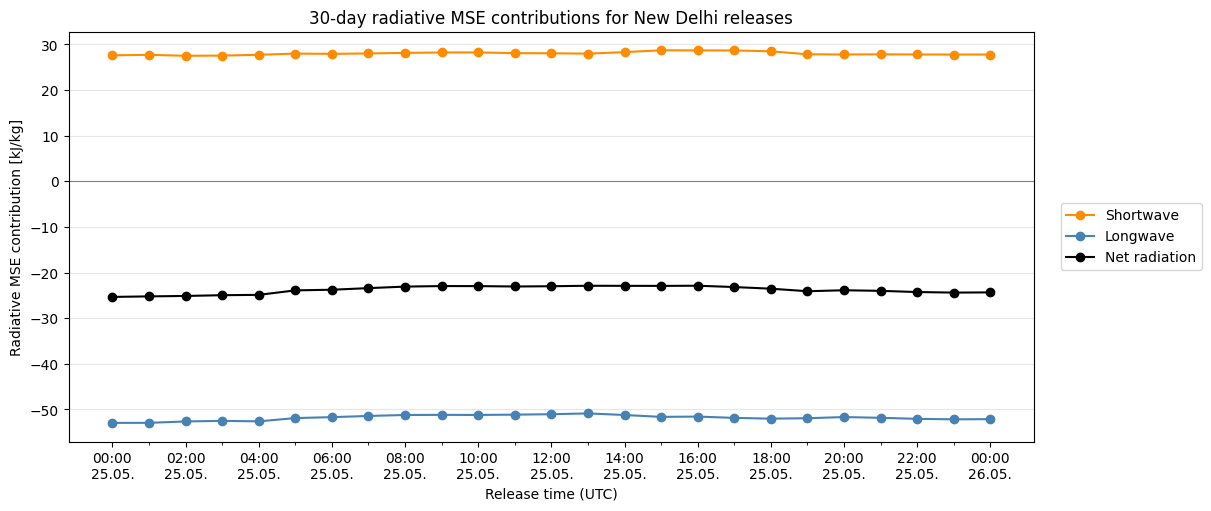

In [ ]:
rad = radiation_budget.join(boundary_budget[["release_time"]])
rad = rad.sort_values("release_time")
release_time = pd.to_datetime(rad["release_time"])

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")

for column, label, color in [
    ("rad_sw", "Shortwave", "darkorange"),
    ("rad_lw", "Longwave", "steelblue"),
    ("rad_net", "Net radiation", "black"),
]:
    ax.plot(release_time, rad[column] / 1000, "o-", color=color, label=label)

ax.axhline(0, color="0.5", linewidth=0.8)
ax.set_xticks(release_time.iloc[::2])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m."))
ax.set_xlabel("Release time (UTC)")
ax.set_ylabel("Radiative MSE contribution [kJ/kg]")
ax.set_title("30-day radiative MSE contributions for New Delhi releases")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.show()

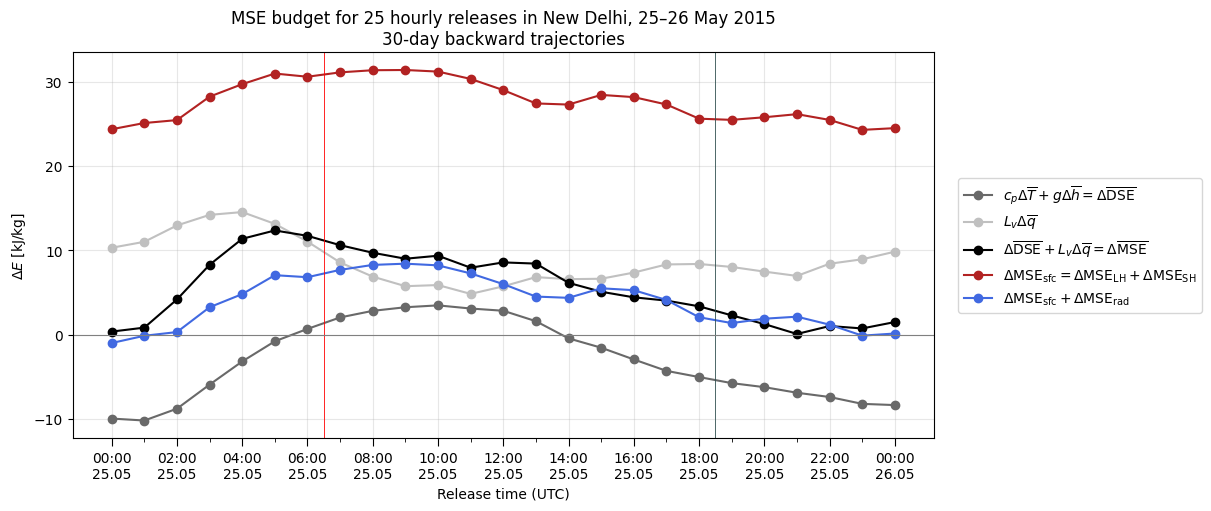

In [ ]:
boundary_budget["delta_mse_reconstructed"] = (
    boundary_budget["sfc_total"] + radiation_budget["rad_net"]
)

budget = boundary_budget.sort_values("release_time")
release_time = pd.to_datetime(budget["release_time"])
label_every = 2

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")

ax.plot(
    release_time,
    (budget["delta_cpT"] + budget["delta_gh"]) / 1000,
    marker="o",
    color="dimgray",
    label=r"$c_p \Delta \overline{T} + g \Delta \overline{h}"
          r" = \Delta \overline{\mathrm{DSE}}$",
)

ax.plot(
    release_time,
    budget["delta_Lvq"] / 1000,
    marker="o",
    color="silver",
    label=r"$L_v \Delta \overline{q}$",
)

ax.plot(
    release_time,
    budget["delta_mse_est"] / 1000,
    marker="o",
    color="black",
    label=r"$\Delta \overline{\mathrm{DSE}} + L_v \Delta \overline{q}"
          r" = \Delta \overline{\mathrm{MSE}}$",
)

ax.plot(
    release_time,
    budget["sfc_total"] / 1000,
    marker="o",
    color="firebrick",
    label=r"$\Delta \mathrm{MSE}_{\mathrm{sfc}}"
          r" = \Delta \mathrm{MSE}_{\mathrm{LH}} + \Delta \mathrm{MSE}_{\mathrm{SH}}$",
)

ax.plot(
    release_time,
    budget["delta_mse_reconstructed"] / 1000,
    marker="o",
    color="royalblue",
    label=r"$\Delta \mathrm{MSE}_{\mathrm{sfc}} + \Delta \mathrm{MSE}_{\mathrm{rad}}$",
)

day = release_time.iloc[0].normalize()
ax.axvline(day + pd.Timedelta(hours=6, minutes=30), color="red", linewidth=0.6)
ax.axvline(day + pd.Timedelta(hours=18, minutes=30), color="darkslategrey", linewidth=0.6)
ax.axhline(0, color="gray", linewidth=0.8)

ax.set_xticks(release_time.iloc[::label_every])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m"))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)

ax.set_xlabel("Release time (UTC)")
ax.set_ylabel(r"$\Delta E$ [kJ/kg]")
ax.set_title(
    "MSE budget for 25 hourly releases in New Delhi, 25–26 May 2015\n"
    "30-day backward trajectories"
)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))